<a href="https://colab.research.google.com/github/aicoder243/lastname100-/blob/main/K_MEANS_HIERCHICAL_CLUSTERING_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customer Data:
   Age  Spending
0   20        20
1   22        25
2   25        30
3   28        35
4   30        40
5   35        60
6   40        70
7   42        75
8   45        80
9   50        90

K-Means Results:
   Age  Spending  KMeans_Cluster
0   20        20               0
1   22        25               0
2   25        30               0
3   28        35               0
4   30        40               0
5   35        60               1
6   40        70               1
7   42        75               1
8   45        80               1
9   50        90               1

Hierarchical Clustering Results:
   Age  Spending  KMeans_Cluster  Hierarchical_Cluster
0   20        20               0                     0
1   22        25               0                     0
2   25        30               0                     0
3   28        35               0                     0
4   30        40               0                     0
5   35        60               1                     

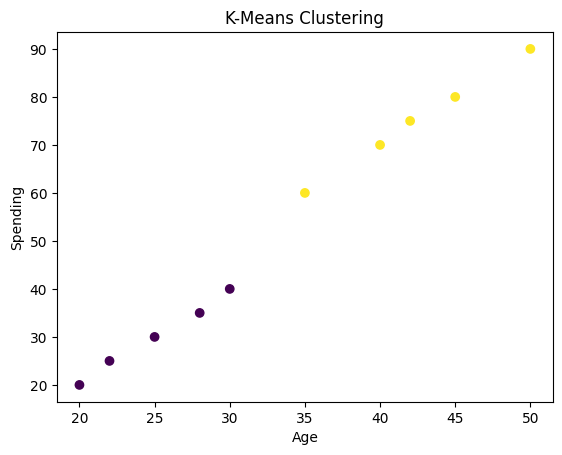

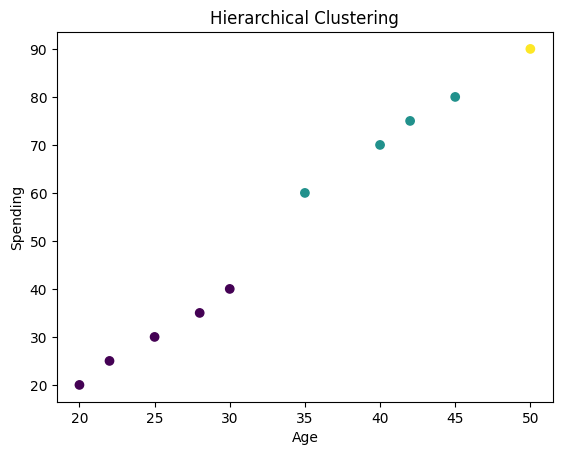

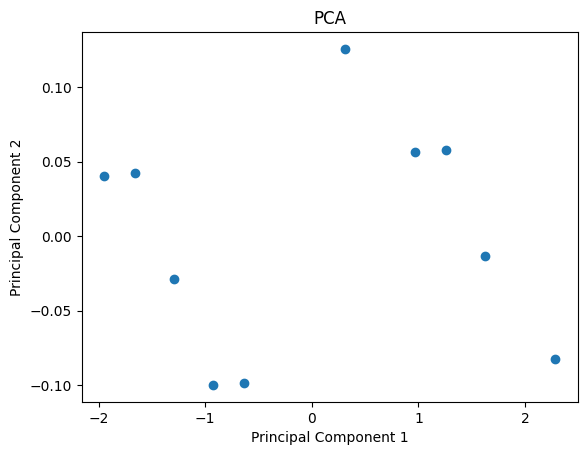

In [ ]:
# K-Means, Hierarchical Clustering, and PCA
# example using customer data

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. Create a simple dataset
# --------------------------------------------------

data = {
    "Age": [20, 22, 25, 28, 30, 35, 40, 42, 45, 50],
    "Spending": [20, 25, 30, 35, 40, 60, 70, 75, 80, 90]
}

df = pd.DataFrame(data)

print("Customer Data:")
print(df)

# Features used for clustering
X = df[["Age", "Spending"]]


# --------------------------------------------------
# 2. Standardize the data
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# --------------------------------------------------
# 3. K-MEANS CLUSTERING
# --------------------------------------------------

kmeans = KMeans(n_clusters=2, random_state=42, n_init=1)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Results:")
print(df)


# --------------------------------------------------
# 4. HIERARCHICAL CLUSTERING
# --------------------------------------------------

hierarchical = AgglomerativeClustering(n_clusters=3)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Clustering Results:")
print(df)


# --------------------------------------------------
# 5. PCA
# --------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

print("\nPCA Results:")
print(df[["Age", "Spending", "PC1", "PC2"]])

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)


# --------------------------------------------------
# 6. Visualize K-Means
# --------------------------------------------------

plt.scatter(
    df["Age"],
    df["Spending"],
    c=df["KMeans_Cluster"]
)

plt.xlabel("Age")
plt.ylabel("Spending")
plt.title("K-Means Clustering")
plt.show()


# --------------------------------------------------
# 7. Visualize Hierarchical Clustering
# --------------------------------------------------

plt.scatter(
    df["Age"],
    df["Spending"],
    c=df["Hierarchical_Cluster"]
)

plt.xlabel("Age")
plt.ylabel("Spending")
plt.title("Hierarchical Clustering")
plt.show()


# --------------------------------------------------
# 8. Visualize PCA
# --------------------------------------------------

plt.scatter(
    df["PC1"],
    df["PC2"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA")
plt.show()